# Assignment 2 - Analysis: dense optimisation and CSR sparse multiplication

**Research questions.** (A) How do loop reordering (`ikj`) and cache blocking
(`block`) affect dense $O(n^3)$ multiplication time and memory relative to the
validated `ijk` baseline? (B) Under which tested sparsity levels does a CSR sparse
representation beat the dense methods on matched logical inputs, once conversion
costs are measured separately?

This notebook consumes the raw measurements produced by `scripts/run_benchmark.py`
and produces every table and figure used in the report
(`reports/Assignment02_DelgadoValera_Report.tex`).

- Inputs: `data/results/raw_timings.csv`, `configs.csv`, `conversions.csv`,
  `blocksize_tuning.csv`, `environment.json`
- Outputs: `data/results/summary.csv`, `reports/figures/fig{1..5}_*.{pdf,png}`

In [1]:
%matplotlib inline
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..") if (Path("..") / "data").exists() else Path(".")
RES = ROOT / "data" / "results"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300,
                     "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})

raw = pd.read_csv(RES / "raw_timings.csv")
cfg = pd.read_csv(RES / "configs.csv")
conv = pd.read_csv(RES / "conversions.csv")
tune = pd.read_csv(RES / "blocksize_tuning.csv")
env = json.loads((RES / "environment.json").read_text(encoding="utf-8"))

BUDGET_S = env["protocol"]["budget_s"]
DENSE = ["ijk", "ikj", "block"]
METHODS = DENSE + ["csr"]
COLORS = {"ijk": "#4c72b0", "ikj": "#dd8452",
          "block": "#55a868", "csr": "#c44e52"}

meas = raw[(raw["phase"] == "measure") & raw["kernel_per_mult_ns"].notna()].copy()
meas["per_ms"] = meas["kernel_per_mult_ns"].astype(float) / 1e6

## 1. Environment and protocol

Snapshot taken before the campaign with `scripts/collect_env.py`. The campaign ran
with the Windows *High performance* power scheme so that single-core clocks stay at
turbo frequency (a first campaign under *Balanced* showed 2-5x frequency swings and
was discarded).

In [2]:
rows = [
    ("CPU", f"{env['cpu_name'].strip()} | {env['cpu_physical_cores']} physical / "
            f"{env['cpu_logical_cores']} logical processors"),
    ("Cache", f"L1d 48 KB/core, L2 total {env['cache']['l2_total_kb']} KB, "
              f"L3 {env['cache']['l3_total_kb']} KB, line 64 B"),
    ("RAM", f"{env['ram_total_bytes'] / 1e9:.1f} GB"),
    ("OS", env["platform"]),
    ("C compiler", f"{env['gcc_version']} ({env['protocol']['compiler_flags']})"),
    ("NumPy (inputs only)", env["numpy_version"]),
    ("Power scheme", env.get("power_scheme", "").split("(")[-1].rstrip(")")),
    ("Git commit", env["git_commit"][:12] + (" (dirty)" if env["git_dirty"] else "")),
    ("Sizes (Part A)", ", ".join(map(str, env["protocol"]["sizes"]))),
    ("Sparsities (Part B)",
     ", ".join(f"{p}%" for p in env["protocol"]["sparsity_levels_percent"])
     + f" at n = {env['protocol']['sparse_n']}"),
    ("Warm-ups / reps",
     f"{env['protocol']['warmups']} / {env['protocol']['reps']} "
     f"(batch floor {env['protocol']['min_batch_ns'] / 1e6:.0f} ms)"),
    ("Affinity", env["protocol"]["affinity"]),
    ("Budgets", f"{BUDGET_S} s per multiplication, "
                f"{env['protocol']['mem_limit_bytes'] / 1e9:.0f} GiB peak RSS"),
]
print(pd.DataFrame(rows, columns=["item", "value"]).to_string(index=False))

               item                                                                                                value
                CPU                            13th Gen Intel(R) Core(TM) i7-1355U | 10 physical / 12 logical processors
              Cache                                             L1d 48 KB/core, L2 total 6656 KB, L3 12288 KB, line 64 B
                RAM                                                                                              16.8 GB
                 OS                                                                            Windows-10-10.0.26200-SP0
         C compiler gcc (MinGW-W64 x86_64-ucrt-mcf-seh, built by Brecht Sanders, r1) 16.1.0 (-O2 -std=c11 -Wall -Wextra)
NumPy (inputs only)                                                                                                2.2.6
       Power scheme                                                                                     Alto rendimiento
         Git commit             

## 2. Correctness before benchmarking

`src/matmul2.exe selftest` runs 304 checks (all pass): sizes 1-64 x patterns
(full / 50% zeros / zero / identity) x block sizes 4-64, comparing every method
against a `long double` reference (`rtol = 1e-10`, `atol = 1e-12`), bitwise between
methods, plus manual nnz counts and known answers. The campaign CSVs provide an
independent end-to-end check: for each matched input the four methods must emit the
same checksum.

In [3]:
ck = meas.groupby(["n", "sparsity"])["checksum"].nunique()
print(f"(n, sparsity) groups: {len(ck)} | max distinct checksums per group: "
      f"{ck.max()} (1 = all methods agree bitwise)")
print("statuses:", cfg.groupby(["phase", "status"]).size().to_dict())

(n, sparsity) groups: 16 | max distinct checksums per group: 1 (1 = all methods agree bitwise)
statuses: {('a', 'ok'): 21, ('b', 'ok'): 36}


## 3. Per-configuration statistics

Median and IQR over the measured repetitions (warm-ups excluded). All 57
configurations completed; there are no timeouts to report in this campaign.

In [4]:
stats = []
for (method, n, sp), g in meas.groupby(["method", "n", "sparsity"]):
    med = g["per_ms"].median()
    q1, q3 = g["per_ms"].quantile(0.25), g["per_ms"].quantile(0.75)
    stats.append({"method": method, "n": n, "sparsity": sp, "reps": len(g),
                  "median_ms": med, "iqr_ms": q3 - q1,
                  "iqr_pct": 100 * (q3 - q1) / med,
                  "gflops": 2 * n**3 / med / 1e3})
summary = pd.DataFrame(stats)
st = cfg.set_index(["method", "n", "sparsity"])[["peak_rss_mb", "sys_cpu_mean_pct"]]
summary = summary.merge(st, left_on=["method", "n", "sparsity"],
                        right_index=True, how="left")

partA = summary[summary["sparsity"] == 0].pivot_table(
    index="n", columns="method", values="median_ms")
partA.round(3)

method,block,ijk,ikj
n,,,
10,0.001,0.000,0.000
50,0.039,0.033,0.023
100,0.340,0.300,0.213
200,2.848,3.216,1.844
500,41.544,75.071,29.550
1000,325.152,806.866,286.129
2000,2525.301,27477.615,3941.174


## 4. Part A: runtime scaling vs the cubic model

Figure 1: median kernel time per multiplication against $n$ (log-log) with IQR
error bars and a reference line proportional to $n^3$ anchored at the baseline.

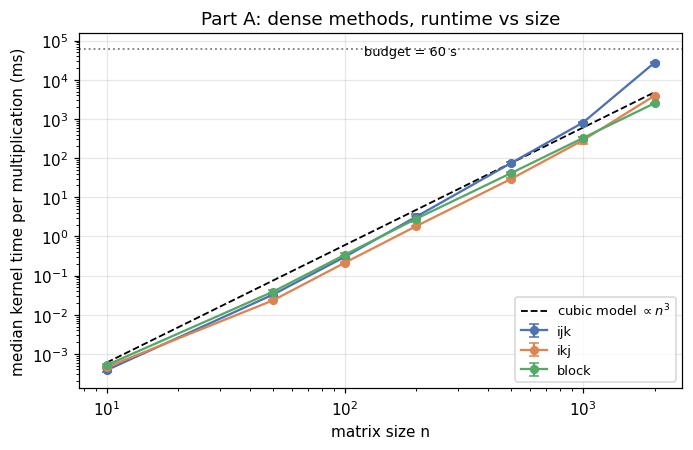

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for m in DENSE:
    s = summary[(summary["method"] == m) & (summary["sparsity"] == 0)].sort_values("n")
    ax.errorbar(s["n"], s["median_ms"], yerr=s["iqr_ms"], fmt="o-", capsize=3,
                color=COLORS[m], label=m, markersize=5)

n_ref = np.array([10, 2000])
ref_base = partA.loc[500, "ijk"]
ax.plot(n_ref, ref_base * (n_ref / 500) ** 3, "k--", lw=1.2,
        label=r"cubic model $\propto n^3$")
ax.axhline(BUDGET_S * 1000, color="gray", ls=":", lw=1.2)
ax.text(120, BUDGET_S * 1000 * 0.72, f"budget = {BUDGET_S} s", fontsize=8.5)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("matrix size n")
ax.set_ylabel("median kernel time per multiplication (ms)")
ax.set_title("Part A: dense methods, runtime vs size")
ax.legend(fontsize=8.5)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIG / f"fig1_runtime_loglog.{ext}")
plt.show()

## 5. Part A: speedups over the baseline

Figure 2: $T_{ijk}/T_{method}$ for the optimised methods. Blocking only pays off
once the $B$ matrix outgrows the last-level cache; below that, plain `ikj` is the
faster optimisation on this CPU.

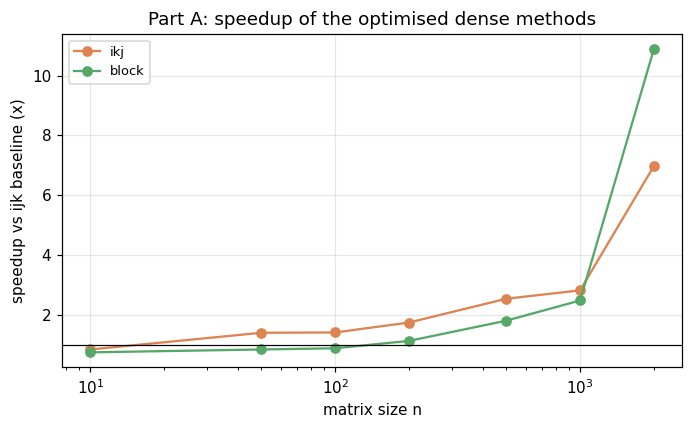

block vs ikj (ikj time / block time):
n
10      0.887
50      0.601
100     0.626
200     0.647
500     0.711
1000    0.880
2000    1.561


In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4.0))
base = partA["ijk"]
for m in ("ikj", "block"):
    ax.plot(partA.index, base / partA[m], "o-", color=COLORS[m], label=m)
ax.axhline(1.0, color="k", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("matrix size n")
ax.set_ylabel("speedup vs ijk baseline (x)")
ax.set_title("Part A: speedup of the optimised dense methods")
ax.legend(fontsize=8.5)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIG / f"fig2_speedup.{ext}")
plt.show()
print("block vs ikj (ikj time / block time):")
print((partA["ikj"] / partA["block"]).round(3).to_string())

## 6. Block-size tuning

Figure 3: median kernel time in the tuning sweep (block sizes 16/32/64/128,
n in {500, 1000, 2000}). The campaign used the median-best block size per $n$
(64 everywhere).

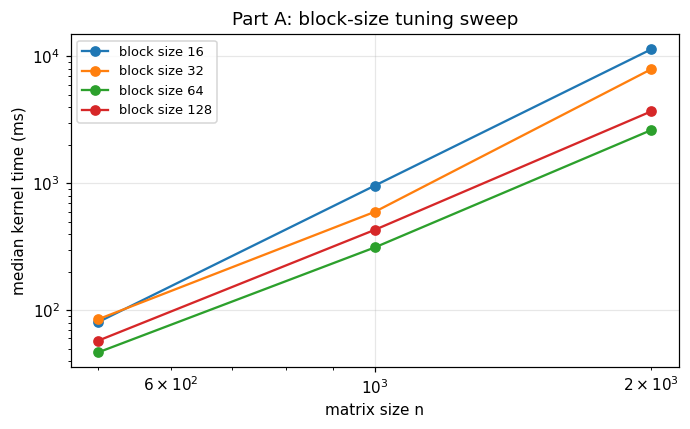

best block size per n: {500: np.int64(64), 1000: np.int64(64), 2000: np.int64(64)}


In [7]:
fig, ax = plt.subplots(figsize=(6.4, 4.0))
tm = tune.groupby(["blocksize", "n"])["kernel_per_mult_ns"].median().unstack() / 1e6
for bs in tm.index:
    ax.plot(tm.columns, tm.loc[bs], "o-", label=f"block size {bs}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("matrix size n")
ax.set_ylabel("median kernel time (ms)")
ax.set_title("Part A: block-size tuning sweep")
ax.legend(fontsize=8.5)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIG / f"fig3_blocksize.{ext}")
plt.show()
print("best block size per n:", dict(tm.idxmin()))

## 7. Part B: runtime vs sparsity at n = 1000

Figure 4: median kernel time (log y-axis) for all four methods. The dense loops
ignore zeros (flat curves); only CSR tracks the number of nonzeros.

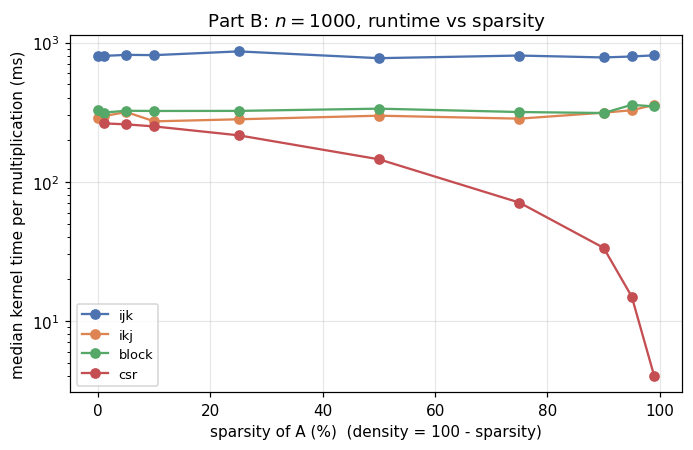

method,block,csr,ijk,ikj
sparsity (%),,,,
0,325.2,NaN,806.9,286.1
1,314.0,262.7,802.4,296.0
5,323.6,258.3,816.8,316.8
10,322.4,249.6,812.9,271.5
25,322.9,215.5,864.9,280.9
50,335.0,144.8,773.1,298.2
75,316.9,70.7,807.4,283.9
90,311.8,33.4,782.4,313.5
95,357.0,14.9,794.8,326.2


In [8]:
pb = summary[summary["n"] == 1000].pivot_table(
    index="sparsity", columns="method", values="median_ms")
pb.index.name = "sparsity (%)"

fig, ax = plt.subplots(figsize=(6.4, 4.2))
for m in METHODS:
    ax.plot(pb.index, pb[m], "o-", color=COLORS[m], label=m)
ax.set_yscale("log")
ax.set_xlabel("sparsity of A (%)  (density = 100 - sparsity)")
ax.set_ylabel("median kernel time per multiplication (ms)")
ax.set_title(r"Part B: $n = 1000$, runtime vs sparsity")
ax.legend(fontsize=8.5)
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIG / f"fig4_sparse_runtime.{ext}")
plt.show()
pb.round(1)

## 8. Conversion cost and memory

Figure 5: (a) median dense-to-CSR conversion time, measured separately from the
multiplication; (b) peak resident memory of the child process at $n = 1000$
(`GetProcessMemoryInfo`, sampled by the orchestrator as well).

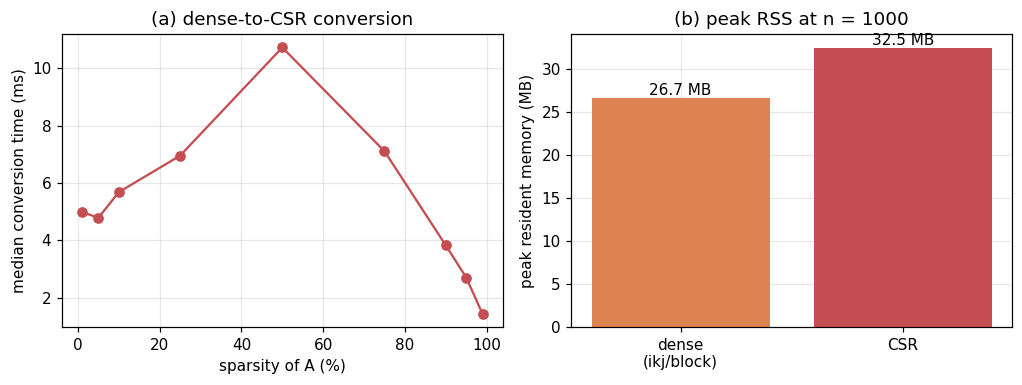

median conversion ms by sparsity:
sparsity
1      4.99
5      4.79
10     5.69
25     6.96
50    10.73
75     7.11
90     3.83
95     2.71
99     1.44


In [9]:
cm = conv.groupby("sparsity")["convert_ns"].median() / 1e6

mem = summary[summary["n"] == 1000].groupby("method")["peak_rss_mb"].mean()
mem_csr = summary[(summary["n"] == 1000) & (summary["method"] == "csr")]
mem_dense = summary[(summary["n"] == 1000) & (summary["method"] != "csr")]

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6))
axes[0].plot(cm.index, cm, "o-", color=COLORS["csr"])
axes[0].set_xlabel("sparsity of A (%)")
axes[0].set_ylabel("median conversion time (ms)")
axes[0].set_title("(a) dense-to-CSR conversion")

bp = axes[1].bar(["dense\n(ikj/block)", "CSR"],
                 [mem_dense["peak_rss_mb"].mean(), mem_csr["peak_rss_mb"].mean()],
                 color=[COLORS["ikj"], COLORS["csr"]])
axes[1].bar_label(bp, fmt="%.1f MB")
axes[1].set_ylabel("peak resident memory (MB)")
axes[1].set_title("(b) peak RSS at n = 1000")
fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(FIG / f"fig5_conversion_memory.{ext}")
plt.show()
print("median conversion ms by sparsity:")
print(cm.round(2).to_string())

## 9. Key numbers for the report

Speedups, the CSR/dense crossover and the conversion break-even, all recomputed
from the raw CSVs. `data/results/summary.csv` is regenerated here.

In [10]:
summary.to_csv(RES / "summary.csv", index=False)

key = pd.DataFrame({
    "n": partA.index,
    "ikj_vs_ijk": (partA["ijk"] / partA["ikj"]).round(2),
    "block_vs_ijk": (partA["ijk"] / partA["block"]).round(2),
    "block_vs_ikj": (partA["ikj"] / partA["block"]).round(2),
})
print("Part A speedups:")
print(key.to_string(index=False))

best_dense = pb[["ijk", "ikj", "block"]].min(axis=1)
crossover = pb[pb["csr"] < best_dense].index.min()
print(f"\nCSR beats the best dense method from {crossover:.0f}% sparsity upward "
      f"(tested grid).")

for sp in (50, 90):
    ikj_t, csr_t = pb.loc[sp, "ikj"], pb.loc[sp, "csr"]
    conv_t = cm.loc[sp]
    be = conv_t / (ikj_t - csr_t)
    print(f"sparsity {sp}%: conversion {conv_t:.2f} ms amortises after "
          f"{be:.2f} multiplications")

print(f"\nIQR/median across all configs: median {summary['iqr_pct'].median():.1f}%, "
      f"max {summary['iqr_pct'].max():.1f}%")
print(f"peak RSS: dense max {mem_dense['peak_rss_mb'].max():.1f} MB, "
      f"CSR max {mem_csr['peak_rss_mb'].max():.1f} MB")

Part A speedups:
   n  ikj_vs_ijk  block_vs_ijk  block_vs_ikj
  10        0.84          0.75          0.89
  50        1.40          0.84          0.60
 100        1.41          0.88          0.63
 200        1.74          1.13          0.65
 500        2.54          1.81          0.71
1000        2.82          2.48          0.88
2000        6.97         10.88          1.56

CSR beats the best dense method from 1% sparsity upward (tested grid).
sparsity 50%: conversion 10.73 ms amortises after 0.07 multiplications
sparsity 90%: conversion 3.83 ms amortises after 0.01 multiplications

IQR/median across all configs: median 4.3%, max 17.8%
peak RSS: dense max 26.7 MB, CSR max 38.1 MB
